# Predicting Sleep Duration from Daily Activity
## Data Exploration, Preparation and Modelling

### Project goal
This project investigates whether a participant’s daytime activity can help predict how long they sleep the following night.

### Dataset
This project uses the [PMData dataset](https://osf.io/vx4bk/overview), which contains records of participants’ activity, sleep, exercise, wellbeing, and physical measurements.

Original files will be kept unchanged. All preparation happens in memory, inside this notebook.

### Purpose of this notebook
This notebook covers the whole project in one place. It combines data exploration and preprocessing to:

- Understand the file structure, available measurements, participant identifiers, and dates.
- Verify the sleep target and select relevant input variables.
- Identify missing values, duplicates, and inconsistent records.
- Clean and combine the selected data across participants.
- Match each day’s information to the following night’s main sleep episode.
- Document the decisions made along the way.

The prepared table is then used to train and evaluate the model later in this same notebook.

### Preventing information leakage
We predict sleep duration at 21:00, using activity recorded since the participant woke up. Steps and recorded activity sessions after 21:00 are not included. Days without a recorded wake-up time before 21:00 are excluded.

Measurements from the night being predicted, such as its sleep stages or sleep score, must not be used as inputs. Transformations that learn from the data, such as scaling or filling missing values using averages, will be fitted on training data in the modelling stage.

### Expected output
The intended output is a table with **one row per participant per prediction day**, containing participant and date identifiers, selected daytime summaries up to 21:00, the previous nights' sleep, and the following night's sleep duration as the target.

Once the table is ready, the notebook continues with model training and evaluation, and concludes with a summary of the decisions made, data limitations, and remaining questions.


## 1. Setup
Import pandas to read and work with tables, `Path` to build file paths, and matplotlib with seaborn for plots. Add other libraries only when needed.


In [43]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_DIR = Path("data/raw/pmdata")
# Each participant has a folder named p01, p02, and so on.
participant_folders = sorted(DATA_DIR.glob("p[0-9][0-9]"))

if not participant_folders:
    raise FileNotFoundError(f"No participant folders found in {DATA_DIR.resolve()}")


## 2. Which participants have the relevant files?
Start with sleep, steps, and exercise sessions (which contain the active minutes) for a simple first model. Check Google Docs and wellness as optional additions. Food images are outside this first model’s scope.

The table below checks whether files exist; it does not yet check whether their dates overlap or their values are complete. Missing optional files are not a reason to exclude a participant.


In [44]:
files_to_check = {
    "sleep": "fitbit/sleep.json",
    "steps": "fitbit/steps.json",
    "exercise": "fitbit/exercise.json",
    "google_reports_optional": "googledocs/reporting.csv",
    "wellness_optional": "pmsys/wellness.csv",
}

availability_rows = []
for folder in participant_folders:
    row = {"participant_id": folder.name}
    for name, relative_path in files_to_check.items():
        row[name] = (folder / relative_path).is_file()
    availability_rows.append(row)

availability = pd.DataFrame(availability_rows).set_index("participant_id")
availability


,sleep,steps,exercise,google_reports_optional,wellness_optional
participant_id,,,,,
p01,True,True,True,True,True
p02,True,True,True,True,True
p03,True,True,True,True,True
p04,True,True,True,True,True
p05,True,True,True,True,True
p06,True,True,True,True,True
p07,True,True,True,True,True
p08,True,True,True,True,True
p09,True,True,True,True,True


From this table, we can see that participant 15 does not have Google Forms data, which includes daily meals, weight, fluid intake, and alcohol consumption. This could matter if we use those inputs later, but our initial model will use sleep, steps, and activity minutes, so we can keep participant 15 for now.

All participants have the files we need to start. Next, we need to check what is actually inside the sleep files, because having a file does not mean every night was recorded.


## 3. Is the sleep data usable?
We need sleep duration because it is the value our model will predict. Before using it, we need to know how many nights each participant has recorded, whether any required values are missing, and whether there are any duplicates.

First, load the main-sleep records into one table. Keep the participant, sleep ID, date, start and end times, and minutes asleep. The ID helps us recognize repeated episodes; the times will help us match sleep to daytime activity later. We are not loading the detailed sleep stages because we do not need them for this target.


In [45]:
# Select the needed fields and give them clearer names.
sleep_columns = {
    "logId": "sleep_id",
    "dateOfSleep": "sleep_date",
    "startTime": "start_time",
    "endTime": "end_time",
    "minutesAsleep": "minutes_asleep",
}

sleep_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/sleep.json", convert_dates=False)
    # Keep main sleep rather than naps, and record who it belongs to.
    main_sleep = records.loc[records["mainSleep"].eq(True), list(sleep_columns)].copy()
    main_sleep["participant_id"] = folder.name
    sleep_tables.append(main_sleep)

# Combine the participants into one table.
sleep = pd.concat(sleep_tables, ignore_index=True).rename(columns=sleep_columns)
sleep.head(10)


,sleep_id,sleep_date,start_time,end_time,minutes_asleep,participant_id
0,24486013387,2019-11-02,2019-11-02 00:09:30,2019-11-02T07:19:30.000,378,p01
1,24497341340,2019-11-03,2019-11-03 00:32:00,2019-11-03T07:34:30.000,378,p01
2,24507914069,2019-11-04,2019-11-03 23:55:30,2019-11-04T06:35:00.000,361,p01
3,24521896102,2019-11-05,2019-11-05 00:22:30,2019-11-05T06:25:00.000,326,p01
4,24534036899,2019-11-06,2019-11-06 00:25:30,2019-11-06T06:29:30.000,341,p01
5,24544805751,2019-11-07,2019-11-06 23:45:30,2019-11-07T05:52:00.000,312,p01
6,24544805751,2019-11-07,2019-11-06 23:45:30,2019-11-07T05:52:00.000,312,p01
7,24557456459,2019-11-08,2019-11-07 23:48:30,2019-11-08T06:21:00.000,360,p01
8,24568877484,2019-11-09,2019-11-09 00:31:30,2019-11-09T07:02:30.000,344,p01
9,24579324569,2019-11-10,2019-11-10 00:15:30,2019-11-10T07:18:00.000,382,p01


### Check coverage and basic problems
Convert dates and durations so we can count and compare them. Unreadable values become missing values. A row needs attention if a required value is missing, its duration is not positive, or its end time is not after its start time.

Use the same date window for everyone: the earliest through latest main-sleep date in the downloaded data. This measures coverage across the available dataset, not just each person’s own first-to-last record. It does not establish when each person was expected to participate.


In [46]:
# Convert dates and durations; unreadable values become missing.
for column in ["sleep_date", "start_time", "end_time"]:
    sleep[column] = pd.to_datetime(sleep[column], errors="coerce", format="mixed")
sleep["minutes_asleep"] = pd.to_numeric(sleep["minutes_asleep"], errors="coerce")

study_dates = pd.date_range(sleep["sleep_date"].min(), sleep["sleep_date"].max())
print(f"Observed dataset window: {study_dates[0]:%d %b %Y} to {study_dates[-1]:%d %b %Y}")
print(f"Dates in this window: {len(study_dates)}")


Observed dataset window: 01 Nov 2019 to 01 Apr 2020
Dates in this window: 153


In the table below:
- **Records** counts all main-sleep entries; 
- **Recorded nights** counts different sleep dates.
- **Missing nights** counts dates in the shared window with no main-sleep entry. A missing night does not mean zero sleep but rather that there is no available data for it (days without a recorded wake-up are left out later, and nights without a record stay as missing values, not zeros).
- **Rows to check** counts entries with missing or invalid required values.
- **Extra repeated IDs** counts entries beyond the first with the same participant and sleep ID. Matching copies are removed below; differing records must be investigated.


In [47]:
# Flag incomplete or invalid rows, and extra copies of each sleep ID.
needs_check = (
    sleep.isna().any(axis=1)
    | sleep["minutes_asleep"].le(0)
    | sleep["end_time"].le(sleep["start_time"])
)
repeated_ids = sleep["sleep_id"].notna() & sleep.duplicated(["participant_id", "sleep_id"])

# Summarise by participant without looping through their records.
sleep_coverage = (
    sleep.assign(needs_check=needs_check, repeated_ids=repeated_ids)
    .groupby("participant_id").agg(**{
        "Records": ("sleep_date", "size"),
        "Recorded nights": ("sleep_date", "nunique"),
        "Rows to check": ("needs_check", "sum"),
        "Extra repeated IDs": ("repeated_ids", "sum"),
    })
    .rename_axis("Participant")
)
sleep_coverage.insert(2, "Missing nights", len(study_dates) - sleep_coverage["Recorded nights"])
sleep_coverage


,Records,Recorded nights,Missing nights,Rows to check,Extra repeated IDs
Participant,,,,,
p01,155,150,3,0,5
p02,146,142,11,0,4
p03,81,78,75,0,3
p04,149,144,9,0,5
p05,123,118,35,0,5
p06,155,150,3,0,5
p07,146,142,11,0,4
p08,137,133,20,0,4
p09,141,136,17,0,5


The repeated entries are identical copies, so we keep one of each.


In [48]:
# Remove exact duplicates without changing the raw files.
sleep_clean = sleep.drop_duplicates(ignore_index=True)
print(f"Removed {len(sleep) - len(sleep_clean)} duplicates; {len(sleep_clean):,} sleep records remain.")


Removed 61 duplicates; 1,881 sleep records remain.


We also calculate the average sleep across the last three calendar nights, as this was found during the research we did. Each night is averaged with the two calendar nights before it. If some of them are missing, the average uses the nights that were recorded. Later, each day is matched to the average ending on its morning, so it only uses nights that have already ended before 21:00.

In [49]:
# Average each night with the two calendar nights before it.
# Rows are sorted by participant and date, so the results line up with the table.
sleep_clean = sleep_clean.sort_values(["participant_id", "sleep_date"]).reset_index(drop=True)
sleep_clean["avg_sleep_last_3_nights"] = (
    sleep_clean
    .groupby("participant_id")
    .rolling("3D", on="sleep_date")["minutes_asleep"]
    .mean()
    .to_numpy()
)

sleep_clean[["participant_id", "sleep_date", "minutes_asleep", "avg_sleep_last_3_nights"]].head(10)

,participant_id,sleep_date,minutes_asleep,avg_sleep_last_3_nights
0,p01,2019-11-02,378,378.000000
1,p01,2019-11-03,378,378.000000
2,p01,2019-11-04,361,372.333333
3,p01,2019-11-05,326,355.000000
4,p01,2019-11-06,341,342.666667
5,p01,2019-11-07,312,326.333333
6,p01,2019-11-08,360,337.666667
7,p01,2019-11-09,344,338.666667
8,p01,2019-11-10,382,362.000000
9,p01,2019-11-11,318,348.000000


Now that the sleep records are prepared, we use each participant's recorded wake-up time to define that day's activity window.

The window starts when their main sleep ends and finishes at 21:00. Later, we will add up the activity recorded within that window.

In [50]:
# Use the main sleep's end as the recorded wake-up time.
prediction_days = sleep_clean[[
    "participant_id",
    "sleep_date",
    "end_time"
]].rename(columns={
    "sleep_date": "date",
    "end_time": "wake_up_time"
})

# Set a prediction time of 21:00 for each date.
prediction_days["prediction_time"] = (
    prediction_days["date"] + pd.Timedelta(hours=21)
)

# We need a recorded wake-up time that is earlier than the cutoff.
prediction_days = prediction_days.loc[
    prediction_days["wake_up_time"].notna()
    & (prediction_days["wake_up_time"] < prediction_days["prediction_time"])
].copy()

prediction_days.head(10)

,participant_id,date,wake_up_time,prediction_time
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00
5,p01,2019-11-07,2019-11-07 05:52:00,2019-11-07 21:00:00
6,p01,2019-11-08,2019-11-08 06:21:00,2019-11-08 21:00:00
7,p01,2019-11-09,2019-11-09 07:02:30,2019-11-09 21:00:00
8,p01,2019-11-10,2019-11-10 07:18:00,2019-11-10 21:00:00
9,p01,2019-11-11,2019-11-11 06:05:00,2019-11-11 21:00:00


We have cleaned the sleep records and defined the activity windows. Next, we will prepare the activity measurements before combining them with sleep.

## 4. Prepare the activity records
We will use steps and active minutes to describe each participant’s daytime activity. First, we inspect the files to understand their dates and values.

In [51]:
# Inspect one participant's steps before loading everyone's data.
steps_example = pd.read_json(
    participant_folders[4] / "fitbit/steps.json",
    convert_dates=False
)

steps_example.sample(15)

,dateTime,value
6641,2019-11-09 12:54:00,0
973,2019-11-01 23:08:00,0
69836,2020-01-30 11:43:00,0
25077,2019-12-04 11:39:00,0
48577,2020-01-03 19:19:00,0
82010,2020-02-15 20:28:00,0
87570,2020-03-02 07:57:00,48
29727,2019-12-10 16:31:00,21
2139,2019-11-03 15:23:00,0
86578,2020-02-29 20:32:00,19


We can see that step measurements are spread out through the day, so now we will combine all steps for a single day into one, instead of having so many entries. But before that we need to check for exact duplicates and delete them if there are any.

In [52]:
# Check whether any minute appears more than once.
print(f" Number of duplicate rows is: {steps_example["dateTime"].duplicated().sum()}")

 Number of duplicate rows is: 0


Since there are no duplicates we will continue with the merging of entries. For each day, we use the wake-up time and the 21:00 prediction time from `prediction_days`, and only add up the steps taken between them, so steps after the prediction time are not included.

In [53]:
# Convert the timestamps so pandas can group them by date.
steps_example["dateTime"] = pd.to_datetime(steps_example["dateTime"])
steps_example["date"] = steps_example["dateTime"].dt.normalize()

# Match each minute to that day's wake-up time and 21:00 cutoff.
example_days = prediction_days.loc[
    prediction_days["participant_id"] == participant_folders[4].name
]
example_window = steps_example.merge(example_days, on="date")
example_window = example_window.loc[
    (example_window["dateTime"] >= example_window["wake_up_time"])
    & (example_window["dateTime"] < example_window["prediction_time"])
]

# Add up the steps taken between waking up and 21:00 for each day.
daily_steps = (
    example_window
    .groupby("date")["value"]
    .sum()
    .rename("steps")
    .reset_index()
)

daily_steps.sample(10)

,date,steps
50,2019-12-29,7521
96,2020-03-10,4579
26,2019-12-03,7810
104,2020-03-18,15634
86,2020-02-16,10057
52,2019-12-31,15266
10,2019-11-16,6538
65,2020-01-14,12154
14,2019-11-21,11257
106,2020-03-20,7231


Now that we know how to turn the step values into daily ones, we will continue with exploring the moderately active minutes file to see if we can actually make use of it.

In [54]:
# Read Fitbit's separate measurement of moderately active minutes.
moderate_example = pd.read_json(
    participant_folders[0] / "fitbit/moderately_active_minutes.json",
    convert_dates=False
)

moderate_example.head(10)

,dateTime,value
0,2019-11-01 00:00:00,58
1,2019-11-02 00:00:00,43
2,2019-11-03 00:00:00,63
3,2019-11-04 00:00:00,23
4,2019-11-05 00:00:00,22
5,2019-11-06 00:00:00,10
6,2019-11-07 00:00:00,11
7,2019-11-08 00:00:00,38
8,2019-11-09 00:00:00,31
9,2019-11-10 00:00:00,34


Moderately active minutes are recorded as daily totals, which wouldn't really fit our use case as we need recorded activity from wake up time all the way up until 21:00. Using the full totals could include activity that happened after our prediction, so we cannot use them as today's inputs. We need records that show when the activity happened. There is also an `exercise.json` file, so we will look inside it to see whether it gives us the timings and activity levels we need.

In [55]:
exercise_tables = []

# Read each participant's sessions and attach their ID.
for folder in participant_folders:
    records = pd.read_json(
        folder / "fitbit/exercise.json",
        convert_dates=False
    )
    records["participant_id"] = folder.name
    exercise_tables.append(records)

exercise_records = pd.concat(exercise_tables, ignore_index=True)

exercise_records.head(15)

,logId,activityName,activityTypeId,activityLevel,averageHeartRate,calories,duration,activeDuration,steps,logType,...,source,tcxLink,speed,pace,vo2Max,participant_id,swimLengths,poolLength,poolLengthUnit,customHeartRateZones
0,26451905128,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,192,1331000,1331000,1878.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
1,26455950499,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,302,2202000,2202000,2786.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
2,26467488515,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",98.0,354,2458000,2458000,3035.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
3,26520401069,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",97.0,145,1024000,1024000,1284.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
4,26538035127,Walk,90013,"[{'minutes': 3, 'name': 'sedentary'}, {'minute...",93.0,121,973000,973000,1065.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
5,26517400839,Run,90009,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",144.0,396,1465000,1460000,3901.0,tracker,...,"{'type': 'tracker', 'name': 'Versa 2', 'id': '...",https://www.fitbit.com/activities/exercise/265...,9.341901,385.360523,{'vo2Max': 47.37765},p01,NaN,NaN,NaN,NaN
6,26601718322,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",97.0,252,1844000,1844000,2094.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
7,26613177504,Walk,90013,"[{'minutes': 1, 'name': 'sedentary'}, {'minute...",97.0,454,3123000,3123000,4185.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
8,26777647969,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",106.0,470,2867000,2867000,4698.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
9,26664863611,Run,90009,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",146.0,339,1264000,1260000,3384.0,tracker,...,"{'type': 'tracker', 'name': 'Versa 2', 'id': '...",https://www.fitbit.com/activities/exercise/266...,9.713571,370.615486,{'vo2Max': 47.012370000000004},p01,NaN,NaN,NaN,NaN


This table gives us way more information we can work with. Now we are able to see activities throughout the day per participant, also with the type of activity it is, the start time and the duration in ms. It would be nice for the model also to know what type of activity it was and the start end time of it, but I feel like this is way too complex to figure out for the 1st iteration. So I will just sum up all the activity minutes types between wake up time and 21:00. Research showed that intense activity before bed led to decrease in sleep duration, it would be interesting to investigate on my own, so we will also add a `min_since_last_activity` and `last_activity` for the type of activity it was.

In [56]:
# Expand the activity breakdown while keeping each session's details.
levels = pd.json_normalize(
    exercise_records.to_dict("records"),
    record_path="activityLevel",
    meta=["participant_id", "logId", "activityName", "startTime", "duration"]
).drop_duplicates()

# Put the activity categories into separate columns.
exercise_sessions = levels.pivot(
    index=["participant_id", "logId", "activityName", "startTime", "duration"],
    columns="name",
    values="minutes"
).reset_index()

exercise_sessions.columns.name = None
exercise_sessions = exercise_sessions.rename(columns={
    "logId": "session_id",
    "activityName": "activity_type",
    "startTime": "start_time",
    "lightly": "lightly_active_minutes",
    "fairly": "moderately_active_minutes",
    "very": "very_active_minutes"
})

# Calculate the end time and express duration in minutes.
exercise_sessions["start_time"] = pd.to_datetime(
    exercise_sessions["start_time"]
)
duration_ms = pd.to_numeric(exercise_sessions["duration"])

exercise_sessions["end_time"] = (
    exercise_sessions["start_time"]
    + pd.to_timedelta(duration_ms, unit="ms")
)
exercise_sessions["duration_minutes"] = duration_ms / 60_000

# Keep the fields needed for the daily totals and last-activity details.
exercise_sessions = exercise_sessions[[
    "participant_id",
    "session_id",
    "activity_type",
    "start_time",
    "end_time",
    "duration_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]].sort_values("start_time").reset_index(drop=True)

exercise_sessions.head(10)

,participant_id,session_id,activity_type,start_time,end_time,duration_minutes,lightly_active_minutes,moderately_active_minutes,very_active_minutes
0,p03,26446767579,Walk,2019-11-01 11:45:06,2019-11-01 12:24:21,39.250000,4,3,29
1,p01,26451905128,Walk,2019-11-01 14:56:32,2019-11-01 15:18:43,22.183333,0,8,14
2,p05,26472425317,Walk,2019-11-01 18:56:06,2019-11-01 19:14:01,17.916667,3,5,9
3,p01,26455950499,Walk,2019-11-01 19:03:11,2019-11-01 19:39:53,36.700000,1,12,23
4,p06,26421235751,Interval Workout,2019-11-02 08:44:54,2019-11-02 09:25:00,40.100000,0,0,40
5,p06,26465868505,Walk,2019-11-02 11:45:28,2019-11-02 12:07:39,22.183333,0,3,19
6,p01,26467488515,Walk,2019-11-02 13:26:38,2019-11-02 14:07:36,40.966667,0,11,30
7,p05,26480520277,Walk,2019-11-02 23:47:02,2019-11-03 00:12:38,25.600000,0,4,21
8,p06,26476567208,Walk,2019-11-02 23:47:34,2019-11-03 00:03:47,16.216667,0,3,13
9,p09,26477744222,Walk,2019-11-03 00:17:30,2019-11-03 01:45:10,87.666667,23,14,31


### Prepare activity data for all participants
For each participant, we sum the steps taken between wake-up and 21:00, and add up the activity minutes from exercise sessions in the same window. Sessions still going at 21:00 are left out, so no activity after the prediction time is counted. A day with no recorded session gets 0 session minutes. We also keep the type of the last session (`last_activity`) and how many minutes before 21:00 it ended (`min_since_last_activity`). A day with no session gets `None` as its last activity, because nothing happened that day.

In [57]:
# Load every participant's minute-level steps.
step_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/steps.json", convert_dates=False)
    records["participant_id"] = folder.name
    step_tables.append(records.drop_duplicates())

all_steps = pd.concat(step_tables, ignore_index=True)
all_steps["dateTime"] = pd.to_datetime(all_steps["dateTime"])
all_steps["date"] = all_steps["dateTime"].dt.normalize()

# Keep only the steps taken between waking up and 21:00.
steps_in_window = all_steps.merge(prediction_days, on=["participant_id", "date"])
steps_in_window = steps_in_window.loc[
    (steps_in_window["dateTime"] >= steps_in_window["wake_up_time"])
    & (steps_in_window["dateTime"] < steps_in_window["prediction_time"])
]
window_steps = (
    steps_in_window
    .groupby(["participant_id", "date"])["value"]
    .sum()
    .rename("steps")
    .reset_index()
)

# Keep sessions that started after waking up and ended by 21:00.
sessions = exercise_sessions.assign(date=exercise_sessions["start_time"].dt.normalize())
sessions = sessions.merge(prediction_days, on=["participant_id", "date"])
sessions = sessions.loc[
    (sessions["start_time"] >= sessions["wake_up_time"])
    & (sessions["end_time"] <= sessions["prediction_time"])
]

# Add up the activity minutes of those sessions for each day.
minute_columns = [
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]
window_sessions = (
    sessions
    .groupby(["participant_id", "date"])
    .agg(session_count=("session_id", "size"), **{c: (c, "sum") for c in minute_columns})
    .reset_index()
)

# Describe the last session before 21:00.
last_session = sessions.sort_values("end_time").groupby(["participant_id", "date"]).tail(1)
last_session = last_session.assign(
    min_since_last_activity=(
        last_session["prediction_time"] - last_session["end_time"]
    ).dt.total_seconds() / 60
)[["participant_id", "date", "activity_type", "min_since_last_activity"]]
last_session = last_session.rename(columns={"activity_type": "last_activity"})

# Start from the prediction days, so every row has a wake-up time before 21:00.
daily_activity = prediction_days
for table in [window_steps, window_sessions, last_session]:
    daily_activity = daily_activity.merge(
        table, on=["participant_id", "date"], how="left", validate="one_to_one"
    )

# A day without a recorded session has zero session minutes.
session_columns = ["session_count"] + minute_columns
daily_activity[session_columns] = daily_activity[session_columns].fillna(0).astype(int)

# A day without a recorded session has no last activity.
daily_activity["last_activity"] = daily_activity["last_activity"].fillna("None")

daily_activity.head(10)

,participant_id,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00,11063.0,1,0,11,30,Walk,412.400000
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00,13045.0,0,0,0,0,None,NaN
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00,7373.0,0,0,0,0,None,NaN
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00,9574.0,1,13,0,0,Walk,76.366667
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00,5189.0,0,0,0,0,None,NaN
5,p01,2019-11-07,2019-11-07 05:52:00,2019-11-07 21:00:00,4994.0,0,0,0,0,None,NaN
6,p01,2019-11-08,2019-11-08 06:21:00,2019-11-08 21:00:00,9724.0,1,5,11,15,Walk,324.733333
7,p01,2019-11-09,2019-11-09 07:02:30,2019-11-09 21:00:00,12912.0,0,0,0,0,None,NaN
8,p01,2019-11-10,2019-11-10 07:18:00,2019-11-10 21:00:00,13549.0,1,2,8,38,Walk,742.716667
9,p01,2019-11-11,2019-11-11 06:05:00,2019-11-11 21:00:00,8232.0,0,0,0,0,None,NaN


## 5. Combine activity and sleep
Now we put activity and sleep together in one table. Each row will show a participant’s activity for one day, how they slept the night before, and how they slept the following night.
Sleep is dated by the morning it ends. For example, Tuesday night’s sleep is saved under Wednesday’s date, so we match it to Tuesday’s activity.

From the night before, we keep the bedtime, how long they slept, and the 3-night average. Its end time is the wake-up time, which is already in the table. From the following night, we only keep how long they slept, because that is what we predict. Its start and end times describe the night we are predicting, so we leave them out to prevent information leakage.

In [58]:
# Sleep ending on the activity date is the previous night's sleep.
# Its end is the wake-up time, which is already in the table.
previous_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "start_time": "previous_bedtime",
    "minutes_asleep": "previous_sleep_minutes",
}).drop(columns=["sleep_id", "end_time"])

# Keep only the following night's duration, which is what we predict.
following_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "minutes_asleep": "next_sleep_minutes",
})[["participant_id", "date", "next_sleep_minutes"]]

# Match sleep ending on Wednesday to Tuesday's activity.
following_sleep["date"] = following_sleep["date"] - pd.Timedelta(days=1)

# Combine by participant and date, keeping all activity rows.
combined_data = (
    daily_activity
    .merge(
        previous_sleep,
        on=["participant_id", "date"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        following_sleep,
        on=["participant_id", "date"],
        how="left",
        validate="one_to_one"
    )
)

combined_data.head()

,participant_id,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,previous_bedtime,previous_sleep_minutes,avg_sleep_last_3_nights,next_sleep_minutes
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00,11063.0,1,0,11,30,Walk,412.400000,2019-11-02 00:09:30,378,378.000000,378.0
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00,13045.0,0,0,0,0,None,NaN,2019-11-03 00:32:00,378,378.000000,361.0
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00,7373.0,0,0,0,0,None,NaN,2019-11-03 23:55:30,361,372.333333,326.0
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00,9574.0,1,13,0,0,Walk,76.366667,2019-11-05 00:22:30,326,355.000000,341.0
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00,5189.0,0,0,0,0,None,NaN,2019-11-06 00:25:30,341,342.666667,312.0


Now we will use a box plot to see how sleep duration differs between participants. We want to spot unusually short or long nights, large differences between people, and participants whose sleep varies much more than the rest.

These differences do not automatically mean the data is wrong. We will investigate unusual records before deciding whether to exclude anything.

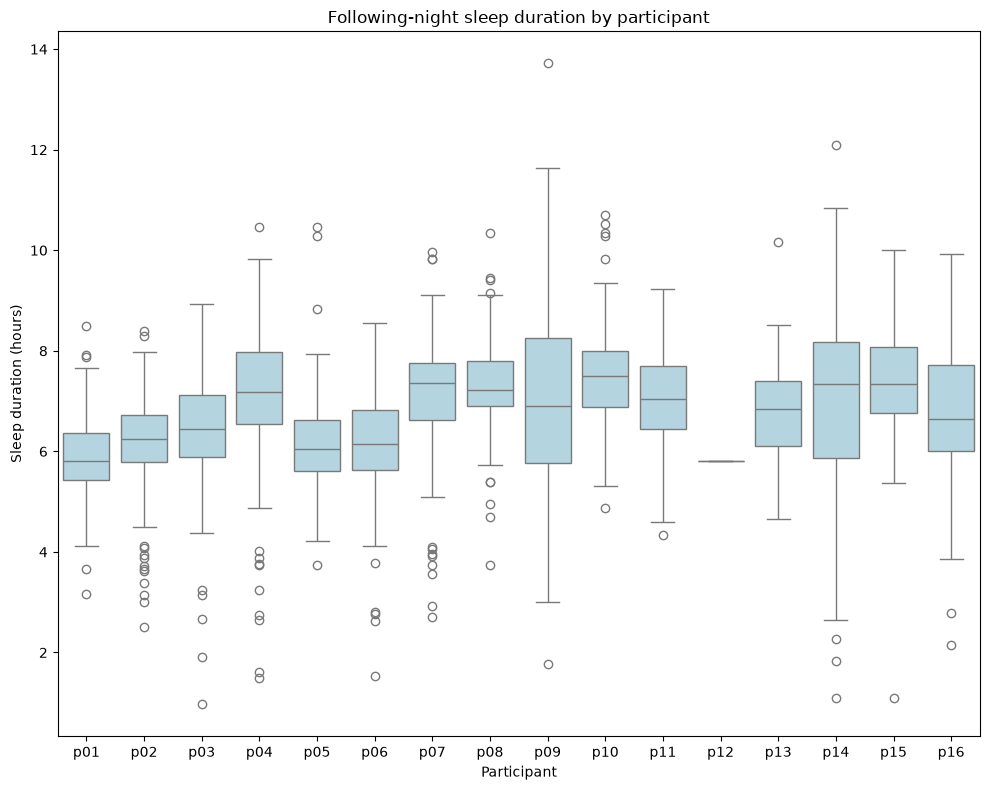

In [59]:
import matplotlib.pyplot as plt


# Convert sleep to hours without changing the combined table.
plot_data = combined_data.assign(
    sleep_hours=combined_data["next_sleep_minutes"] / 60
)

plt.figure(figsize=(10,8))

sns.boxplot(
    data=plot_data,
    x="participant_id",
    y="sleep_hours",
    order=sorted(plot_data["participant_id"].unique()),
    color="lightblue"
)

plt.title("Following-night sleep duration by participant")
plt.xlabel("Participant")
plt.ylabel("Sleep duration (hours)")
plt.tight_layout()
plt.show()

Based on this boxplot we can see that some participants like p09, p14, have large spreads, p12 barely has any nights left, some participants like p02, p04, p07 have lots of outliers, which could mean that there was an issue with their wearables, or maybe it wasn't worn properly, or just that there isn't a significant amount of data we can work with, further analysis of those participants should be done to determine whether we should drop them.

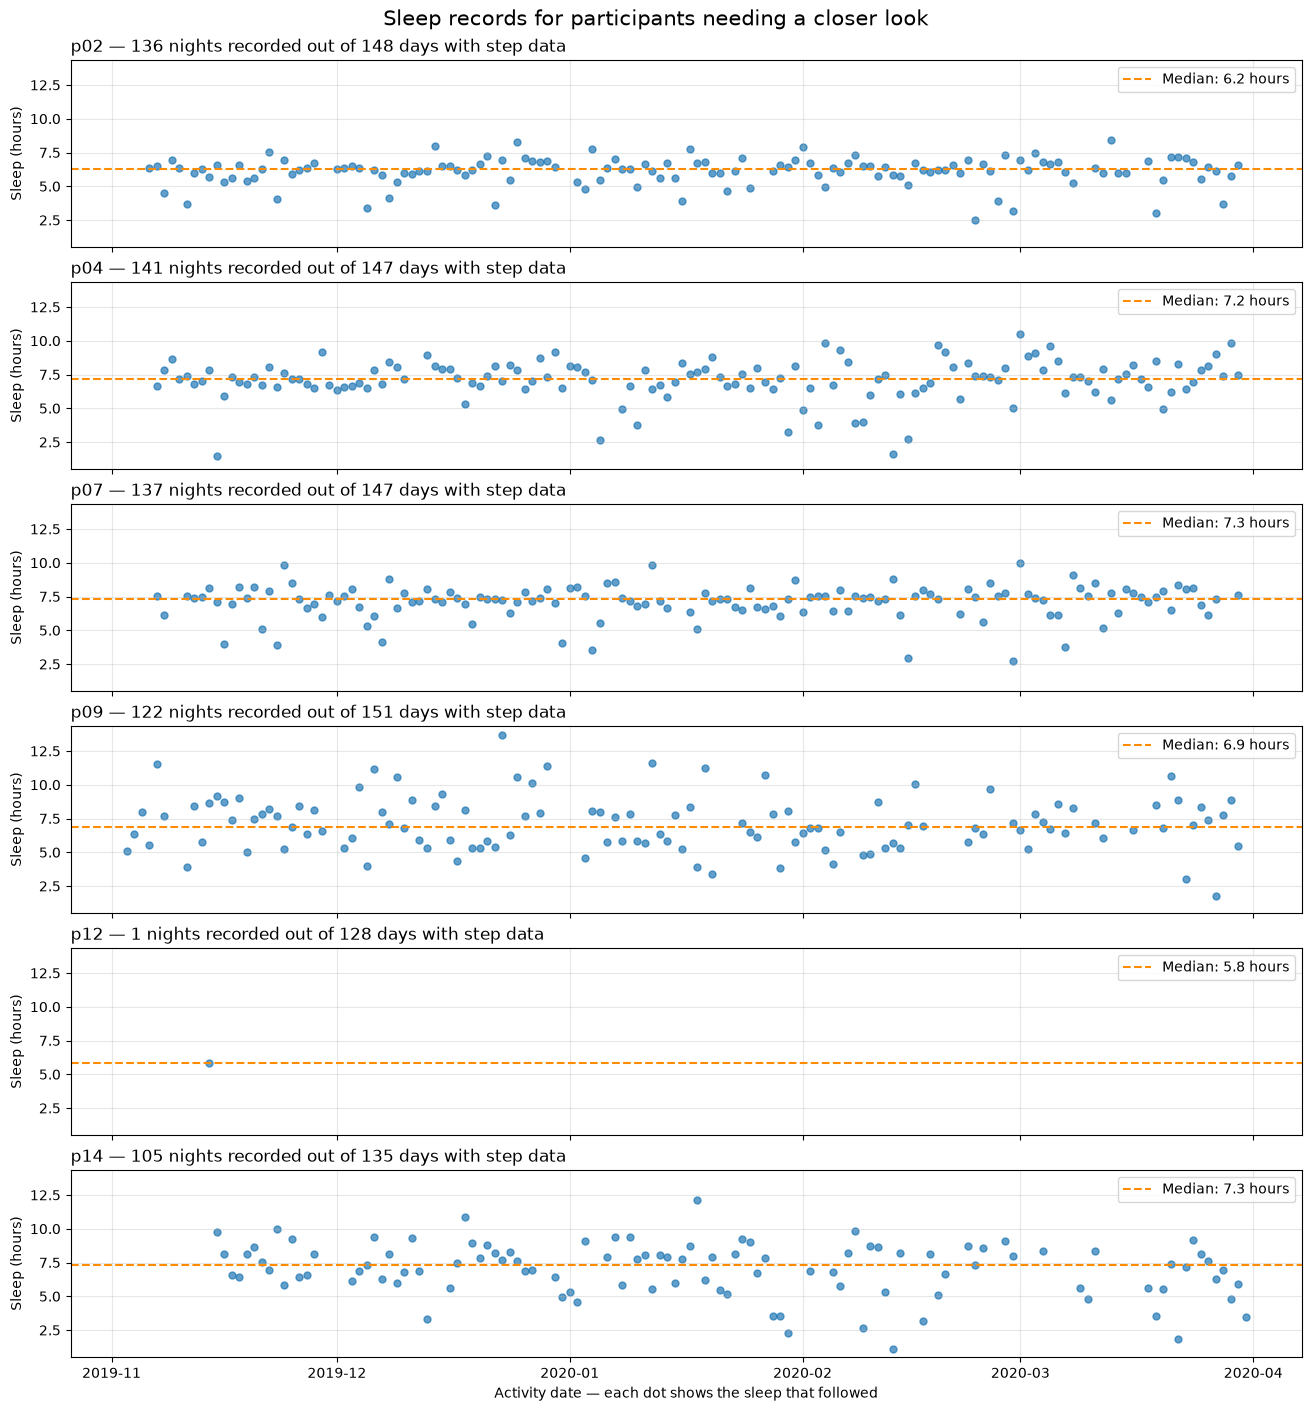

In [60]:
participants_to_check = ["p02", "p04", "p07", "p09", "p12", "p14"]

# Count the days each participant has any step data.
step_days = all_steps.groupby("participant_id")["date"].nunique()

fig, axes = plt.subplots(
    len(participants_to_check), 1,
    figsize=(13, 14),
    sharex=True,
    sharey=True,
    layout="constrained"
)

for ax, participant in zip(axes, participants_to_check):
    person = (
        combined_data.loc[combined_data["participant_id"] == participant]
        .sort_values("date")
    )

    # Only nights with a recorded duration appear as dots.
    recorded = person.dropna(subset=["next_sleep_minutes"])

    ax.scatter(
        recorded["date"],
        recorded["next_sleep_minutes"] / 60,
        s=25,
        alpha=0.7
    )

    # Mark this participant's median sleep duration.
    median_hours = recorded["next_sleep_minutes"].median() / 60

    ax.axhline(
        median_hours,
        color="darkorange",
        linestyle="--",
        label=f"Median: {median_hours:.1f} hours"
    )
    ax.legend(loc="upper right")

    ax.set_title(
        f"{participant} — {len(recorded)} nights recorded "
        f"out of {step_days[participant]} days with step data",
        loc="left"
    )
    ax.set_ylabel("Sleep (hours)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Activity date — each dot shows the sleep that followed")
fig.suptitle("Sleep records for participants needing a closer look", fontsize=15)

plt.show()

Just like I thought we can see that p12 doesn't have many sleep entries, despite having steps recorded on almost all days, so I am leaning towards excluding all p12 related rows. The rest of the participants seem to have outliers, but they are way more manageable to work with, so for the time being I will keep them in the dataset.

In [61]:
# Remove every row that belongs to p12.
rows_before = len(combined_data)
combined_data = combined_data.loc[combined_data["participant_id"] != "p12"].reset_index(drop=True)

print(f"Removed {rows_before - len(combined_data)} p12 rows; {len(combined_data):,} rows remain.")

Removed 6 p12 rows; 1,870 rows remain.


Now that we have excluded p12 from the final table, we need to check how many nights actually will have our TARGET VARIABLE next_sleep_minutes, all other rows can be excluded as our models won't have the final answer they should strive for. The easiest way to do that is by using the describe() function and compare the counts.

In [62]:
combined_data.describe()

,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,min_since_last_activity,previous_bedtime,previous_sleep_minutes,avg_sleep_last_3_nights,next_sleep_minutes
count,1870,1870,1870,1853.000000,1870.000000,1870.000000,1870.000000,1870.000000,1161.000000,1870,1870.000000,1870.000000,1762.000000
mean,2020-01-15 15:39:27.914438,2020-01-15 23:54:10.331550,2020-01-16 12:39:27.914438,10191.196438,1.020321,3.656150,5.438503,30.732620,322.166896,2020-01-15 16:06:59.181818,406.818182,406.248752,406.770148
min,2019-11-01 00:00:00,2019-11-01 04:03:00,2019-11-01 21:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000,2019-11-01 00:59:30,54.000000,54.000000,58.000000
25%,2019-12-11 00:00:00,2019-12-11 07:28:52.500000,2019-12-11 21:00:00,5770.000000,0.000000,0.000000,0.000000,0.000000,179.650000,2019-12-10 23:56:37.500000,360.000000,368.083333,360.000000
50%,2020-01-15 00:00:00,2020-01-15 06:31:15,2020-01-15 21:00:00,10036.000000,1.000000,0.000000,1.000000,14.000000,315.566667,2020-01-14 23:10:15,407.000000,407.583333,407.000000
75%,2020-02-19 00:00:00,2020-02-19 06:44:15,2020-02-19 21:00:00,14558.000000,2.000000,3.000000,8.000000,50.000000,446.266667,2020-02-18 23:04:00,457.000000,445.333333,456.000000
max,2020-04-01 00:00:00,2020-04-01 07:35:00,2020-04-01 21:00:00,38347.000000,7.000000,103.000000,95.000000,330.000000,881.266667,2020-03-31 22:58:30,823.000000,618.000000,823.000000
std,NaN,NaN,NaN,6045.849493,1.070852,8.239263,9.163821,39.972518,184.916317,NaN,84.284818,59.194047,82.008344


Out of 1,870 rows, 1,762 have a `next_sleep_minutes` value. The remaining 108 rows have no target, so we drop them.

In [63]:
# Keep only the rows that have a target.
rows_before = len(combined_data)
combined_data = combined_data.dropna(subset=["next_sleep_minutes"]).reset_index(drop=True)

print(f"Removed {rows_before - len(combined_data)} rows without a target; {len(combined_data):,} rows remain.")

Removed 108 rows without a target; 1,762 rows remain.


A few days still have no steps records, which probably means that there won't be activity records either, to clean the dataset I will just drop them now, so we don't have any issues with them down the road.

In [64]:
# Days without steps after waking up have no activity data at all.
no_steps = combined_data["steps"].isna()
print(f"Days without steps: {no_steps.sum()}")

combined_data = combined_data.loc[~no_steps].reset_index(drop=True)
print(f"{len(combined_data):,} rows remain.")

Days without steps: 6
1,756 rows remain.


### Build the model table
`combined_data` is our final, readable table, so we leave it as it is. For the model, we build a separate table, `model_data`, with only the columns the model will use. Every row keeps its `participant_id` and `date`, so we can always match it back to `combined_data`. These two columns are not inputs; we only need them later to split the data into training and test sets.

The model only understands numbers, so we need to turn the wake-up time and the bedtime into numbers it can work with. A full timestamp like `2019-11-02 07:19` mostly tells the model which day it was, but what matters for sleep is the time of day. So we keep only the clock time, written in hours: 07:15 becomes 7.25.

Bedtime needs one extra step, because it crosses midnight. If we used the plain hour, 23:30 would become 23.5 and 00:30 would become 0.5, which looks like 23 hours apart while it is really just one hour. So we measure bedtime from midnight instead: 23:30 becomes -0.5 and 00:30 becomes 0.5. Bedtimes after noon count as the evening before midnight, and earlier ones count as after midnight.

`prediction_time` is left out, because it is 21:00 on every row, so the model cannot learn anything from it.

In [65]:
# Start from the identifiers, so every row can be matched back to combined_data.
model_data = combined_data[["participant_id", "date"]].copy()

# Turn the wake-up time into hours since midnight, e.g. 07:15 becomes 7.25.
wake_up = combined_data["wake_up_time"]
model_data["wake_up_hour"] = wake_up.dt.hour + wake_up.dt.minute / 60

# Measure bedtime from midnight, so 23:30 becomes -0.5 and 00:30 becomes 0.5.
bedtime = combined_data["previous_bedtime"]
bedtime_hour = bedtime.dt.hour + bedtime.dt.minute / 60
model_data["previous_bedtime_hour"] = bedtime_hour.where(bedtime_hour < 12, bedtime_hour - 24)

# Copy the inputs that are already ready to use, with the target last.
model_columns = [
    "previous_sleep_minutes",
    "avg_sleep_last_3_nights",
    "steps",
    "session_count",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "last_activity",
    "min_since_last_activity",
    "next_sleep_minutes",
]
model_data[model_columns] = combined_data[model_columns]

model_data.head(10)

,participant_id,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,next_sleep_minutes
0,p01,2019-11-02,7.316667,0.150000,378,378.000000,11063.0,1,0,11,30,Walk,412.400000,378.0
1,p01,2019-11-03,7.566667,0.533333,378,378.000000,13045.0,0,0,0,0,None,NaN,361.0
2,p01,2019-11-04,6.583333,-0.083333,361,372.333333,7373.0,0,0,0,0,None,NaN,326.0
3,p01,2019-11-05,6.416667,0.366667,326,355.000000,9574.0,1,13,0,0,Walk,76.366667,341.0
4,p01,2019-11-06,6.483333,0.416667,341,342.666667,5189.0,0,0,0,0,None,NaN,312.0
5,p01,2019-11-07,5.866667,-0.250000,312,326.333333,4994.0,0,0,0,0,None,NaN,360.0
6,p01,2019-11-08,6.350000,-0.200000,360,337.666667,9724.0,1,5,11,15,Walk,324.733333,344.0
7,p01,2019-11-09,7.033333,0.516667,344,338.666667,12912.0,0,0,0,0,None,NaN,382.0
8,p01,2019-11-10,7.300000,0.250000,382,362.000000,13549.0,1,2,8,38,Walk,742.716667,318.0
9,p01,2019-11-11,6.083333,0.150000,318,348.000000,8232.0,0,0,0,0,None,NaN,378.0


`last_activity` is still text, so the model cannot use it yet. Before we turn it into numbers, we check which activity types we actually have and how often each one appears.

In [66]:
model_data["last_activity"].value_counts()

last_activity
None                    643
Walk                    567
Run                     195
Treadmill               151
Outdoor Bike             54
Sport                    39
Weights                  37
Aerobic Workout          14
Hike                     13
Workout                  10
Bike                      7
Cross Country Skiing      6
Spinning                  5
Elliptical                4
Swim                      4
Circuit Training          3
Yoga                      2
Tennis                    1
Skiing                    1
Name: count, dtype: int64

Before we turn the activity types into numbers, we want to see how the following night's sleep looks after each type of activity. Each dot is one night, and the box shows where most of those nights fall.

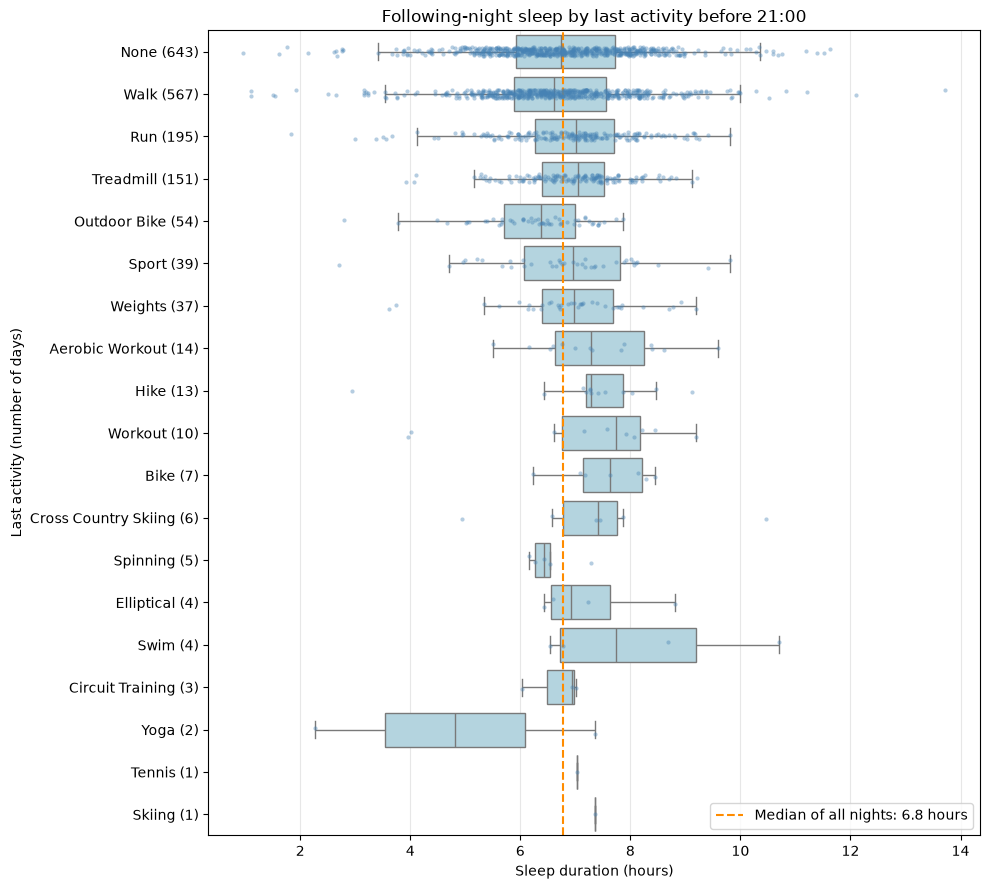

In [67]:
# Show the following night's sleep for each type of last activity.
activity_counts = model_data["last_activity"].value_counts()
activity_plot = model_data.assign(sleep_hours=model_data["next_sleep_minutes"] / 60)

fig, ax = plt.subplots(figsize=(10, 9))

sns.boxplot(
    data=activity_plot,
    x="sleep_hours",
    y="last_activity",
    order=activity_counts.index,
    color="lightblue",
    showfliers=False,
    ax=ax
)
sns.stripplot(
    data=activity_plot,
    x="sleep_hours",
    y="last_activity",
    order=activity_counts.index,
    color="steelblue",
    size=3,
    alpha=0.4,
    ax=ax
)

# Mark the median of all nights, so each activity can be compared with a typical night.
overall_median = activity_plot["sleep_hours"].median()
ax.axvline(
    overall_median,
    color="darkorange",
    linestyle="--",
    label=f"Median of all nights: {overall_median:.1f} hours"
)

# Show how many days each activity has next to its name.
ax.set_yticks(
    range(len(activity_counts)),
    [f"{activity} ({count})" for activity, count in activity_counts.items()]
)

ax.set_title("Following-night sleep by last activity before 21:00")
ax.set_xlabel("Sleep duration (hours)")
ax.set_ylabel("Last activity (number of days)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

From this we can see that values like yoga, tennis and skiing are rarely recorded and also that activities don't have that big of a difference on the person as I had expected. Now we give each activity type its own number. 0 means there was no session that day, and the other types are numbered from most to least common, so the most common one gets 1. The legend below shows which number belongs to which activity, so we can always translate the numbers back.

In [68]:
# Number the activity types from most to least common, keeping 0 for days without a session.
activity_types = model_data["last_activity"].value_counts().drop("None").index
activity_legend = {"None": 0} | {
    activity: number for number, activity in enumerate(activity_types, start=1)
}

model_data["last_activity"] = model_data["last_activity"].map(activity_legend)
activity_legend

{'None': 0,
 'Walk': 1,
 'Run': 2,
 'Treadmill': 3,
 'Outdoor Bike': 4,
 'Sport': 5,
 'Weights': 6,
 'Aerobic Workout': 7,
 'Hike': 8,
 'Workout': 9,
 'Bike': 10,
 'Cross Country Skiing': 11,
 'Spinning': 12,
 'Elliptical': 13,
 'Swim': 14,
 'Circuit Training': 15,
 'Yoga': 16,
 'Tennis': 17,
 'Skiing': 18}

Days without a session have no `min_since_last_activity`. Filling it with 0 would be wrong, because 0 means the session ended right at 21:00. Instead, we use the minutes from wake-up to 21:00: the participant has gone the whole day so far without a session. Since `last_activity` is 0 on those days, the model can still tell them apart from days with a real session. This only uses each day's own wake-up time, so nothing is learned from other rows.

In [69]:
# On days without a session, count the whole time from wake-up to 21:00.
minutes_awake = (
    combined_data["prediction_time"] - combined_data["wake_up_time"]
).dt.total_seconds() / 60
model_data["min_since_last_activity"] = model_data["min_since_last_activity"].fillna(minutes_awake)

# Confirm the model table has no missing values left.
model_data.isna().sum().sum()

np.int64(0)

From the table above we can also see that certain nights have sleep recorded between 2-4h per night, while those might actually be legitamate, I have suspisioun to believe those outliers might be caused by the fitbit band failing to work properly, Further analysis into nights that fall between 1-4h should be done.

In [70]:
# Count the following nights between 1 and 4 hours.
print(f"Number of sleep records between 1-4h {combined_data["next_sleep_minutes"].between(60, 240).sum()}")

Number of sleep records between 1-4h 58


From this count we can see that there are 58 outliers, which is not too many, another thing investigating is the sleep patterns, perhaps the fitbit band might count naps during the day as actual sleep, which wouldn't be useful. Also my suspisioun still stands that there might have been an issue with the wearable during the night. Next we will check for any patterns. To find patterns without deciding them myself, I will use k-means group the short nights by when they started and when they ended. Nights that start and end at similar times end up in the same group. Each dot is one night: when the sleep started goes from left to right, and when it ended goes from bottom to top.

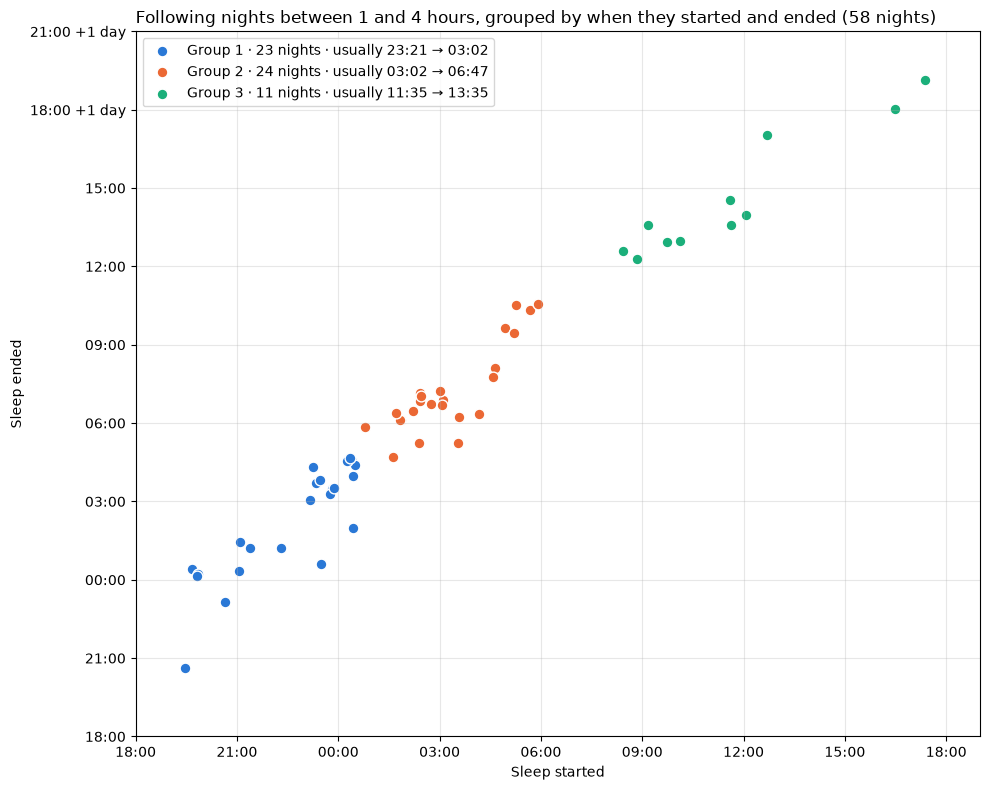

In [71]:
from sklearn.cluster import KMeans


def clock_hours(times):
    """Hours from midnight, with evening times (18:00 or later) counted as negative."""
    hours = times.dt.hour + times.dt.minute / 60
    return hours.where(hours < 18, hours - 24)


def clock_label(hour):
    return f"{int(hour % 24):02d}:{int(hour % 1 * 60):02d}"


# Date every night by the activity day before it, like the following night in combined_data.
nights = sleep_clean.assign(
    date=sleep_clean["sleep_date"] - pd.Timedelta(days=1),
    start_hour=clock_hours(sleep_clean["start_time"]),
    end_hour=clock_hours(sleep_clean["end_time"]),
)
# A sleep that runs past 18:00 ends on the next clock day.
nights["end_hour"] = nights["end_hour"].where(nights["end_hour"] >= nights["start_hour"], nights["end_hour"] + 24)

# Find the short following nights and add when they started and ended.
short_nights = (
    combined_data.loc[
        combined_data["next_sleep_minutes"].between(60, 240),
        ["participant_id", "date", "next_sleep_minutes"]
    ]
    .merge(nights[["participant_id", "date", "start_hour", "end_hour"]], on=["participant_id", "date"])
)

# Let k-means group the nights by start and end time, then number the groups by start time.
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
short_nights["group"] = kmeans.fit_predict(short_nights[["start_hour", "end_hour"]])
group_order = short_nights.groupby("group")["start_hour"].median().sort_values().index
short_nights["group"] = short_nights["group"].map({group: number for number, group in enumerate(group_order, start=1)})

group_colors = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}

fig, ax = plt.subplots(figsize=(10, 8))

for group, nights_in_group in short_nights.groupby("group"):
    typical_start = nights_in_group["start_hour"].median()
    typical_end = nights_in_group["end_hour"].median()

    # Every night in the group as one dot.
    ax.scatter(
        nights_in_group["start_hour"],
        nights_in_group["end_hour"],
        s=60,
        color=group_colors[group],
        edgecolor="white",
        label=(
            f"Group {group} · {len(nights_in_group)} nights · "
            f"usually {clock_label(typical_start)} → {clock_label(typical_end)}"
        )
    )

# Label both axes as clock times, from 18:00 to 18:00 the next day.
start_ticks = range(-6, 19, 3)
ax.set_xticks(start_ticks, [f"{hour % 24:02d}:00" for hour in start_ticks])
ax.set_xlim(-6, 19)

# Sleep can end the next evening, so those times are marked with +1 day.
end_ticks = range(-6, 22, 3)
ax.set_yticks(end_ticks, [f"{hour % 24:02d}:00" + (" +1 day" if hour >= 18 else "") for hour in end_ticks])
ax.set_ylim(-6, 21)

ax.set_title(f"Following nights between 1 and 4 hours, grouped by when they started and ended ({len(short_nights)} nights)", loc="left")
ax.set_xlabel("Sleep started")
ax.set_ylabel("Sleep ended")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As you can see, there is some sort of relevance: the clusters are close, especially group 2. They have a lot of overlaps, whereas group 3 has a lot of differences.

- **Group 1** seems like it could be late naps. People just having late naps could also be people just having to wake up very early.
- **Group 2** actually seems to contain people that go to bed late, and/or nights where people went to bed late and woke up early. Maybe they had a reason to do that, so I would assume that their wearable were working fine, although this is not proper sleep, and you can't really predict these outcomes. I'm not really sure whether those are viable for our use case.
- **Group 3**: I imagine this group is going to be just people taking naps during the day. Perhaps this is not reliable, and we should exclude this group from our dataset.

For this use case, we're definitely dropping group 3 for this iteration, and we'll see how it works with the model.

In [72]:
# Find the participant and date of every night in group 3.
group_3_nights = short_nights.loc[short_nights["group"] == 3, ["participant_id", "date"]]
group_3_keys = group_3_nights.set_index(["participant_id", "date"]).index


def without_group_3(table):
    keys = table.set_index(["participant_id", "date"]).index
    return table.loc[~keys.isin(group_3_keys)].reset_index(drop=True)


# Remove them from both tables, so combined_data and model_data keep matching row for row.
rows_before = len(combined_data)
combined_data = without_group_3(combined_data)
model_data = without_group_3(model_data)

print(f"Removed {rows_before - len(combined_data)} group 3 nights; {len(combined_data):,} rows remain.")

Removed 11 group 3 nights; 1,745 rows remain.


In [73]:
model_data.describe()

,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,next_sleep_minutes
count,1745,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000
mean,2020-01-14 13:12:12.378223,8.207459,0.341156,406.297421,406.007736,10367.808023,1.042407,3.723209,5.545559,31.633811,1.573639,460.635817,408.406304
min,2019-11-01 00:00:00,0.233333,-11.916667,54.000000,54.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000,58.000000
25%,2019-12-10 00:00:00,6.633333,-0.950000,360.000000,369.000000,6075.000000,0.000000,0.000000,0.000000,0.000000,0.000000,256.416667,362.000000
50%,2020-01-14 00:00:00,7.633333,-0.166667,407.000000,407.333333,10169.000000,1.000000,0.000000,1.000000,16.000000,1.000000,411.416667,407.000000
75%,2020-02-17 00:00:00,9.000000,0.866667,456.000000,444.333333,14811.000000,2.000000,3.000000,8.000000,52.000000,2.000000,699.566667,457.000000
max,2020-03-31 00:00:00,20.633333,11.616667,823.000000,618.000000,38347.000000,7.000000,103.000000,95.000000,330.000000,18.000000,1239.000000,823.000000
std,NaN,2.537444,2.459831,83.767031,58.601347,6006.325540,1.073252,8.318189,9.276853,40.052939,2.307098,264.835599,79.571699


## 6. Train and test the model
For this first iteration, we keep things simple: all nights go into one dataset, and we randomly split it into a training set (80%) and a test set (20%). The model only gets the activity and sleep columns as inputs. `participant_id` and `date` are left out, and `next_sleep_minutes` is what it has to predict.

In [74]:
from sklearn.model_selection import train_test_split

# The model only gets the activity and sleep columns as inputs.
inputs = model_data.drop(columns=["participant_id", "date", "next_sleep_minutes"])
target = model_data["next_sleep_minutes"]

# Randomly put 80% of the nights in the training set and 20% in the test set.
inputs_train, inputs_test, target_train, target_test = train_test_split(
    inputs, target, test_size=0.2, random_state=42
)

print(f"Training nights: {len(inputs_train):,}; test nights: {len(inputs_test):,}")

Training nights: 1,396; test nights: 349


The first algorithm we would try is random forest. It works well with our numbered activity types, because it splits the data on the numbers instead of treating them as amounts, and it does not need the inputs to be scaled.

To see how far the predictions are from the truth, we report:

- **Average error (MAE)**: how many minutes the prediction is off on an average night.
- **RMSE**: also in minutes, but big misses count more, so it shows whether there are some very wrong predictions.
- **Accuracy**: on average, how close the prediction is to how long the person actually slept, as a percentage (100% minus the average error in %).
- **R²**: compares the model with always guessing the average sleep. 1 means perfect predictions, 0 means no better than guessing the average, and below 0 means worse.
- **Nights within 30 and 60 minutes**: the share of nights where the prediction was close to the truth.

In [75]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)

# Train the random forest on the training nights only.
random_forest = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
random_forest.fit(inputs_train, target_train)

# Predict the test nights and compare the predictions with the real sleep duration.
predictions = random_forest.predict(inputs_test)
errors = (target_test - predictions).abs()

print(f"Average error (MAE): {mean_absolute_error(target_test, predictions):.0f} minutes")
print(f"RMSE: {root_mean_squared_error(target_test, predictions):.0f} minutes")
print(f"Accuracy: {1 - mean_absolute_percentage_error(target_test, predictions):.1%}")
print(f"R²: {r2_score(target_test, predictions):.2f}")
print(f"Nights within 30 minutes: {(errors <= 30).mean():.1%}")
print(f"Nights within 60 minutes: {(errors <= 60).mean():.1%}")

Average error (MAE): 52 minutes
RMSE: 69 minutes
Accuracy: 86.0%
R²: 0.05
Nights within 30 minutes: 42.1%
Nights within 60 minutes: 65.6%


To see how far each prediction is from the truth, we plot every test night as a dot: the real sleep duration from left to right, and the predicted one from bottom to top. Dots on the black line were predicted perfectly. The dashed lines show a miss of one hour either way, so dots between them were off by less than an hour.

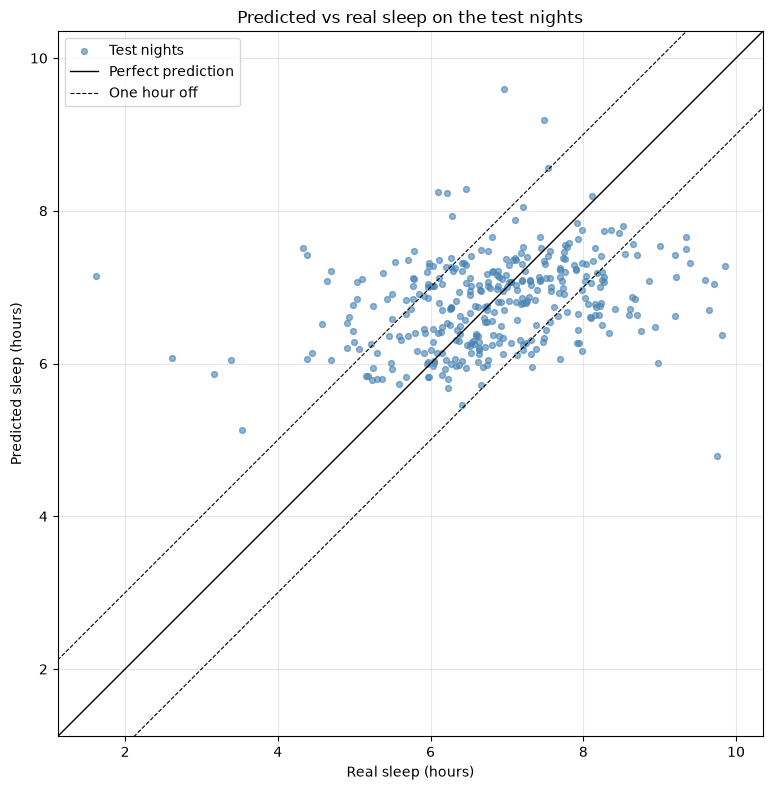

In [76]:
real_hours = target_test / 60
predicted_hours = predictions / 60

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(real_hours, predicted_hours, s=18, color="steelblue", alpha=0.6, label="Test nights")

# The line where the prediction equals the truth, and one hour off either way.
limits = [min(real_hours.min(), predicted_hours.min()) - 0.5, max(real_hours.max(), predicted_hours.max()) + 0.5]
ax.plot(limits, limits, color="black", linewidth=1, label="Perfect prediction")
ax.plot(limits, [limit + 1 for limit in limits], color="black", linestyle="--", linewidth=0.8, label="One hour off")
ax.plot(limits, [limit - 1 for limit in limits], color="black", linestyle="--", linewidth=0.8)

ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal")
ax.set_title("Predicted vs real sleep on the test nights")
ax.set_xlabel("Real sleep (hours)")
ax.set_ylabel("Predicted sleep (hours)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [77]:
importance = random_forest.feature_importances_
columns = inputs_train.columns

random_forest_cof = pd.Series(importance, columns)
random_forest_cof

wake_up_hour                 0.124197
previous_bedtime_hour        0.130066
previous_sleep_minutes       0.133755
avg_sleep_last_3_nights      0.210018
steps                        0.113485
session_count                0.018640
lightly_active_minutes       0.049961
moderately_active_minutes    0.043340
very_active_minutes          0.047500
last_activity                0.023395
min_since_last_activity      0.105642
dtype: float64

<Axes: >

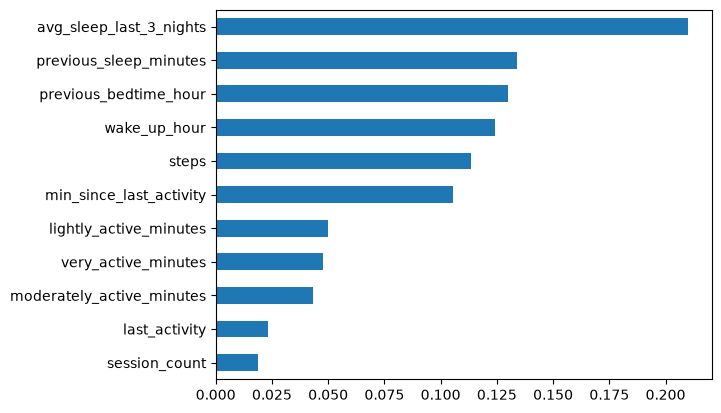

In [78]:
random_forest_cof.sort_values().plot.barh()

To see which inputs the random forest actually relies on, we shuffle one input at a time in the test nights and check how much worse the predictions get. If the error goes up a lot, the model needed that input. If it barely changes, or even gets a little better, the model did not really use it.

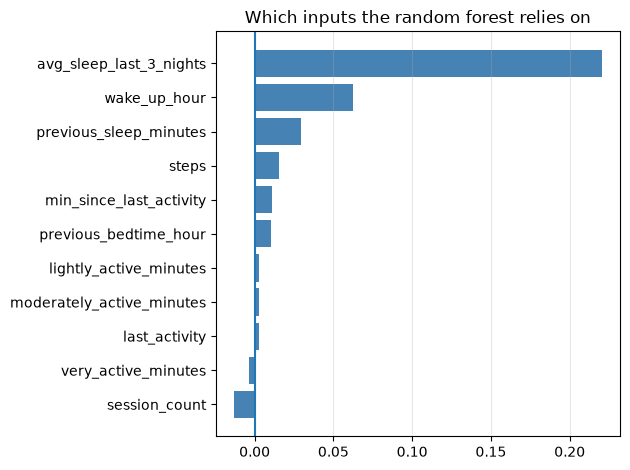

In [ ]:
from sklearn.inspection import permutation_importance

# Shuffle each input in the test nights and measure how much the average error grows.
importance = permutation_importance(
    random_forest,
    inputs_test,
    target_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=23,
    n_jobs=-1
)
input_importance = pd.Series(importance.importances_mean, index=inputs_test.columns).sort_values()

fig, ax = plt.subplots()
ax.barh(input_importance.index, input_importance.values, color="steelblue")
ax.axvline()

ax.set_title("Which inputs the random forest relies on")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()